In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)
from sklearn.calibration import calibration_curve

from scipy.optimize import minimize

# Carregar o dataset
url = (
    "https://raw.githubusercontent.com/primaryobjects/"
    "voice-gender/master/voice.csv"
)

df = pd.read_csv(url)

print("Primeiras linhas do dataset:")
print(df.head())

print("\nDimensões do dataset:")
print(df.shape)

print("\nInformações das colunas:")
df.info()

print("\nValores ausentes:")
print(df.isnull().sum().sum())

Primeiras linhas do dataset:
   meanfreq        sd    median       Q25       Q75       IQR       skew  \
0  0.059781  0.064241  0.032027  0.015071  0.090193  0.075122  12.863462   
1  0.066009  0.067310  0.040229  0.019414  0.092666  0.073252  22.423285   
2  0.077316  0.083829  0.036718  0.008701  0.131908  0.123207  30.757155   
3  0.151228  0.072111  0.158011  0.096582  0.207955  0.111374   1.232831   
4  0.135120  0.079146  0.124656  0.078720  0.206045  0.127325   1.101174   

          kurt    sp.ent       sfm  ...  centroid   meanfun    minfun  \
0   274.402906  0.893369  0.491918  ...  0.059781  0.084279  0.015702   
1   634.613855  0.892193  0.513724  ...  0.066009  0.107937  0.015826   
2  1024.927705  0.846389  0.478905  ...  0.077316  0.098706  0.015656   
3     4.177296  0.963322  0.727232  ...  0.151228  0.088965  0.017798   
4     4.333713  0.971955  0.783568  ...  0.135120  0.106398  0.016931   

     maxfun   meandom    mindom    maxdom   dfrange   modindx  label  
0  0

In [2]:
# X: características da voz
X = df.drop(columns=["label"])

# y: variável que queremos prever
y = df["label"]

print("\nQuantidade de features:", X.shape[1])
print("Quantidade de registros:", X.shape[0])

print("\nDistribuição das classes:")
print(y.value_counts())

print("\nProporção das classes:")
print(y.value_counts(normalize=True) * 100)


Quantidade de features: 20
Quantidade de registros: 3168

Distribuição das classes:
label
male      1584
female    1584
Name: count, dtype: int64

Proporção das classes:
label
male      50.0
female    50.0
Name: proportion, dtype: float64


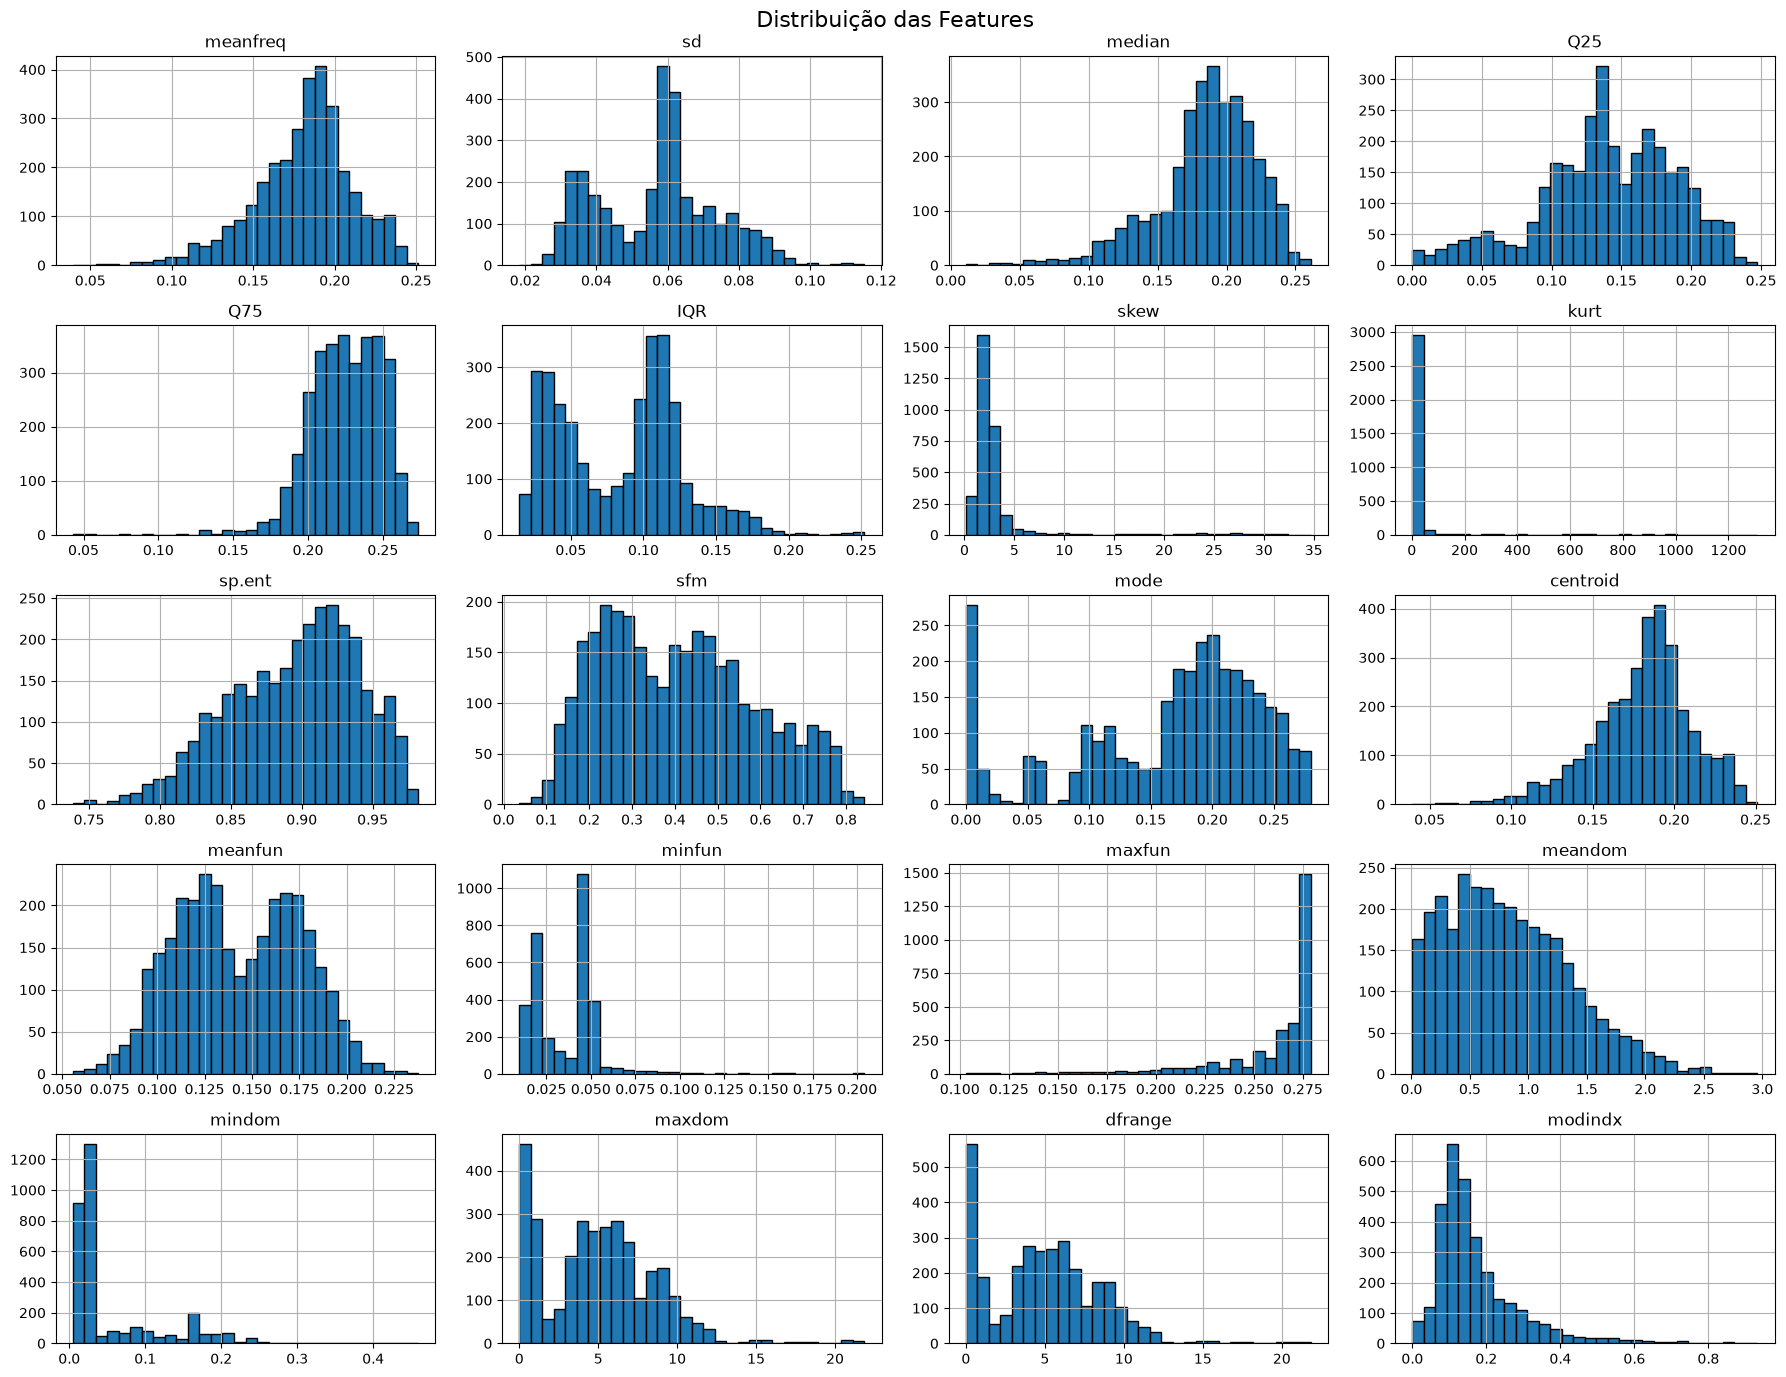

In [3]:
# Histogramas de todas as features
X.hist(
    figsize=(18, 14),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribuição das Features", fontsize=16)
plt.tight_layout()
plt.savefig("distribuicao_features.png", dpi=150)
plt.show()

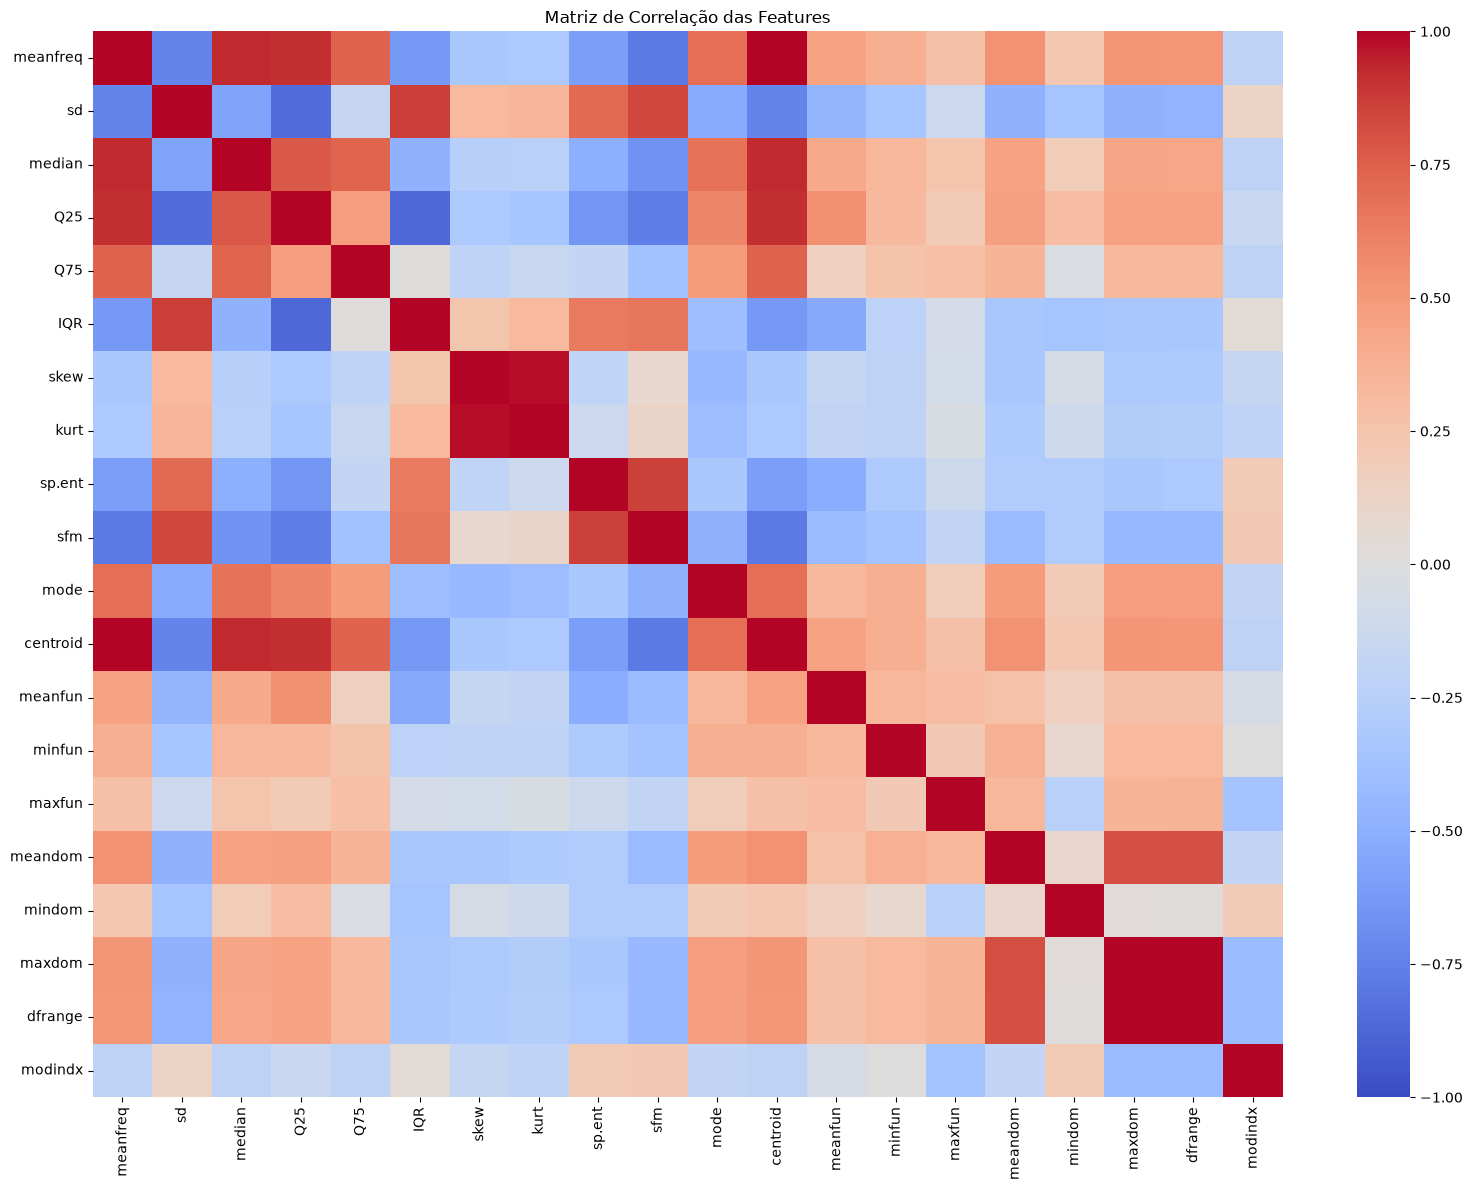

In [4]:
correlacao = X.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlacao,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Matriz de Correlação das Features")
plt.tight_layout()
plt.savefig("matriz_correlacao.png", dpi=150)
plt.show()

In [5]:
# Separação treino/teste: 80% para treino e 20% para teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Treino: (2534, 20)
Teste: (634, 20)


In [6]:
# Pipeline: padronização + regressão logística
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

# Hiperparâmetros que serão testados
param_grid = {
    "model__penalty": ["l1", "l2"],
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# Validação cruzada estratificada com 5 folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("\nMelhores parâmetros:")
print(grid_search.best_params_)

print("\nMelhor acurácia média na validação cruzada:")
print(grid_search.best_score_)


Melhores parâmetros:
{'model__C': 1, 'model__penalty': 'l2'}

Melhor acurácia média na validação cruzada:
0.973161509616359


C:\Users\aleco\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [7]:
resultados = pd.DataFrame(grid_search.cv_results_)

colunas = [
    "param_model__penalty",
    "param_model__C",
    "mean_test_score",
    "std_test_score",
    "mean_train_score"
]

print("\nResultados da validação cruzada:")
print(
    resultados[colunas]
    .sort_values("mean_test_score", ascending=False)
    .to_string(index=False)
)


Resultados da validação cruzada:
param_model__penalty  param_model__C  mean_test_score  std_test_score  mean_train_score
                  l2            1.00         0.973162        0.006453          0.973559
                  l1            1.00         0.972767        0.006054          0.972967
                  l1          100.00         0.971583        0.006691          0.972770
                  l1           10.00         0.971583        0.006691          0.972671
                  l2           10.00         0.971583        0.006691          0.972671
                  l2          100.00         0.971188        0.006332          0.972671
                  l2            0.10         0.970793        0.006554          0.971192
                  l1            0.10         0.970002        0.008438          0.971981
                  l2            0.01         0.960924        0.011428          0.963003
                  l1            0.01         0.960136        0.009888          0.96043


--- AVALIAÇÃO DO MODELO FINAL ---
Acurácia: 0.9747634069400631
Precisão: 0.9659442724458205
Recall: 0.9842271293375394
F1-score: 0.975

Relatório de classificação:
              precision    recall  f1-score   support

      female       0.98      0.97      0.97       317
        male       0.97      0.98      0.97       317

    accuracy                           0.97       634
   macro avg       0.97      0.97      0.97       634
weighted avg       0.97      0.97      0.97       634



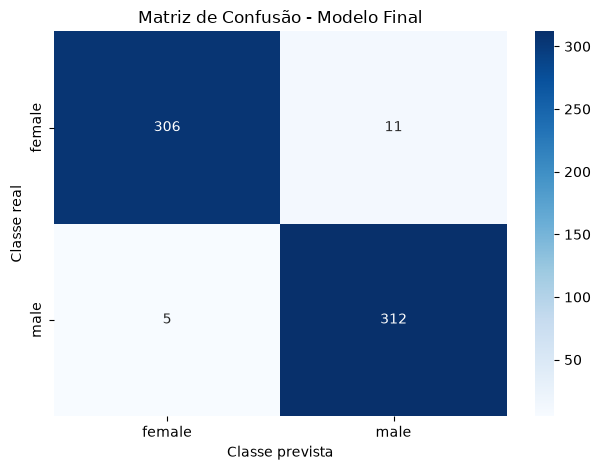

In [8]:
# Recuperar o melhor modelo
modelo_final = grid_search.best_estimator_

# Fazer previsões
y_pred = modelo_final.predict(X_test)

# Calcular métricas
print("\n--- AVALIAÇÃO DO MODELO FINAL ---")

print("Acurácia:", accuracy_score(y_test, y_pred))
print("Precisão:", precision_score(y_test, y_pred, pos_label="male"))
print("Recall:", recall_score(y_test, y_pred, pos_label="male"))
print("F1-score:", f1_score(y_test, y_pred, pos_label="male"))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))

# Matriz de confusão
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["female", "male"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["female", "male"],
    yticklabels=["female", "male"]
)

plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de Confusão - Modelo Final")
plt.tight_layout()
plt.savefig("matriz_confusao.png", dpi=150)
plt.show()

In [9]:
# Encontrar o melhor C separadamente para L1 e L2
comparacao_modelos = {}

for penalidade in ["l1", "l2"]:
    resultados_penalidade = resultados[
        resultados["param_model__penalty"] == penalidade
    ]

    melhor_linha = resultados_penalidade.loc[
        resultados_penalidade["mean_test_score"].idxmax()
    ]

    melhor_c = float(melhor_linha["param_model__C"])

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty=penalidade,
            C=melhor_c,
            solver="liblinear",
            max_iter=5000,
            random_state=42
        ))
    ])

    modelo.fit(X_train, y_train)
    comparacao_modelos[penalidade] = modelo

    print(
        f"Penalização: {penalidade.upper()} | "
        f"Melhor C: {melhor_c} | "
        f"Acurácia CV: {melhor_linha['mean_test_score']:.4f}"
    )

# Criar tabela de coeficientes
coeficientes = pd.DataFrame({
    "feature": X.columns,
    "L1": comparacao_modelos["l1"].named_steps["model"].coef_[0],
    "L2": comparacao_modelos["l2"].named_steps["model"].coef_[0]
})

print("\nCoeficientes L1 e L2:")
print(
    coeficientes
    .assign(
        abs_L1=lambda d: d["L1"].abs(),
        abs_L2=lambda d: d["L2"].abs()
    )
    .sort_values("abs_L1", ascending=False)
    .drop(columns=["abs_L1", "abs_L2"])
    .to_string(index=False)
)

# Features eliminadas pelo Lasso
eliminadas = coeficientes.loc[
    np.isclose(coeficientes["L1"], 0.0),
    "feature"
].tolist()

print("\nFeatures eliminadas pelo Lasso (L1):")
print(eliminadas)
print("Quantidade eliminada:", len(eliminadas))

Penalização: L1 | Melhor C: 1.0 | Acurácia CV: 0.9728
Penalização: L2 | Melhor C: 1.0 | Acurácia CV: 0.9732

Coeficientes L1 e L2:
 feature        L1        L2
 meanfun -5.009986 -4.749050
     IQR  2.314667  1.299491
     sfm -1.612689 -1.560824
  sp.ent  1.537309  1.399573
  minfun  0.558556  0.533211
    kurt -0.518797 -0.381114
 modindx -0.375847 -0.380914
 meandom  0.121714  0.140076
    mode  0.087820  0.125980
     Q75  0.054785  0.622680
      sd  0.054322  0.190164
  mindom -0.039904 -0.060514
  median -0.013024 -0.043112
 dfrange  0.007952  0.002075
     Q25  0.000000 -0.841576
meanfreq  0.000000 -0.103900
centroid  0.000000 -0.103900
    skew  0.000000 -0.158068
  maxfun  0.000000 -0.043819
  maxdom  0.000000  0.001005

Features eliminadas pelo Lasso (L1):
['meanfreq', 'Q25', 'skew', 'centroid', 'maxfun', 'maxdom']
Quantidade eliminada: 6


C:\Users\aleco\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\aleco\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\aleco\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\

In [10]:
class LogisticRegressionRMSE:
    def __init__(self, max_iter=2000):
        self.max_iter = max_iter
        self.coef_ = None
        self.intercept_ = None

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        # Adicionar a coluna do intercepto
        X_bias = np.column_stack([
            np.ones(X.shape[0]),
            X
        ])

        n_features = X_bias.shape[1]

        def funcao_perda(theta):
            z = X_bias @ theta
            p = self.sigmoid(z)

            erros = p - y
            rmse = np.sqrt(np.mean(erros ** 2) + 1e-12)

            # Gradiente da RMSE em relação aos coeficientes
            gradiente = (
                X_bias.T @ (erros * p * (1 - p))
            ) / (len(y) * rmse)

            return rmse, gradiente

        # Inicialização dos coeficientes
        theta_inicial = np.zeros(n_features)

        resultado = minimize(
            funcao_perda,
            theta_inicial,
            method="L-BFGS-B",
            jac=True,
            options={"maxiter": self.max_iter}
        )

        if not resultado.success:
            print(
                "Aviso do otimizador RMSE:",
                resultado.message
            )

        self.intercept_ = resultado.x[0]
        self.coef_ = resultado.x[1:]

        print("\nTreinamento RMSE:")
        print("Convergiu:", resultado.success)
        print("Mensagem:", resultado.message)
        print("RMSE final:", resultado.fun)

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)

        probabilidades = self.sigmoid(
            X @ self.coef_ + self.intercept_
        )

        # Formato compatível com a convenção do scikit-learn
        return np.column_stack([
            1 - probabilidades,
            probabilidades
        ])

    def predict(self, X):
        probabilidades = self.predict_proba(X)[:, 1]
        return (probabilidades >= 0.5).astype(int)

In [11]:
# Padronização: ajustar somente no treino
scaler_rmse = StandardScaler()

X_train_scaled = scaler_rmse.fit_transform(X_train)
X_test_scaled = scaler_rmse.transform(X_test)

# Converter as classes em valores binários
# female = 0; male = 1
y_train_bin = (y_train == "male").astype(int).to_numpy()
y_test_bin = (y_test == "male").astype(int).to_numpy()

# Modelo alternativo com RMSE
modelo_rmse = LogisticRegressionRMSE(max_iter=2000)

modelo_rmse.fit(
    X_train_scaled,
    y_train_bin
)

y_prob_rmse = modelo_rmse.predict_proba(X_test_scaled)[:, 1]
y_pred_rmse = (y_prob_rmse >= 0.5).astype(int)

print("\nAcurácia do modelo RMSE:")
print(accuracy_score(y_test_bin, y_pred_rmse))

print("\nAUC do modelo RMSE:")
print(roc_auc_score(y_test_bin, y_prob_rmse))


Treinamento RMSE:
Convergiu: True
Mensagem: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
RMSE final: 0.1400369316041278

Acurácia do modelo RMSE:
0.9779179810725552

AUC do modelo RMSE:
0.9970942093164425


In [12]:
# Probabilidades do modelo padrão
classes_modelo = list(modelo_final.named_steps["model"].classes_)
indice_male = classes_modelo.index("male")

y_prob_logloss = modelo_final.predict_proba(X_test)[:, indice_male]
y_pred_logloss = (y_prob_logloss >= 0.5).astype(int)

# Comparar as métricas dos dois modelos
comparacao = pd.DataFrame({
    "Modelo": ["Log-loss", "RMSE"],
    "Acurácia": [
        accuracy_score(y_test_bin, y_pred_logloss),
        accuracy_score(y_test_bin, y_pred_rmse)
    ],
    "AUC": [
        roc_auc_score(y_test_bin, y_prob_logloss),
        roc_auc_score(y_test_bin, y_prob_rmse)
    ],
    "RMSE": [
        np.sqrt(np.mean((y_prob_logloss - y_test_bin) ** 2)),
        np.sqrt(np.mean((y_prob_rmse - y_test_bin) ** 2))
    ]
})

print("\nComparação dos modelos:")
print(comparacao.to_string(index=False))


Comparação dos modelos:
  Modelo  Acurácia      AUC     RMSE
Log-loss  0.974763 0.997035 0.141817
    RMSE  0.977918 0.997094 0.138495


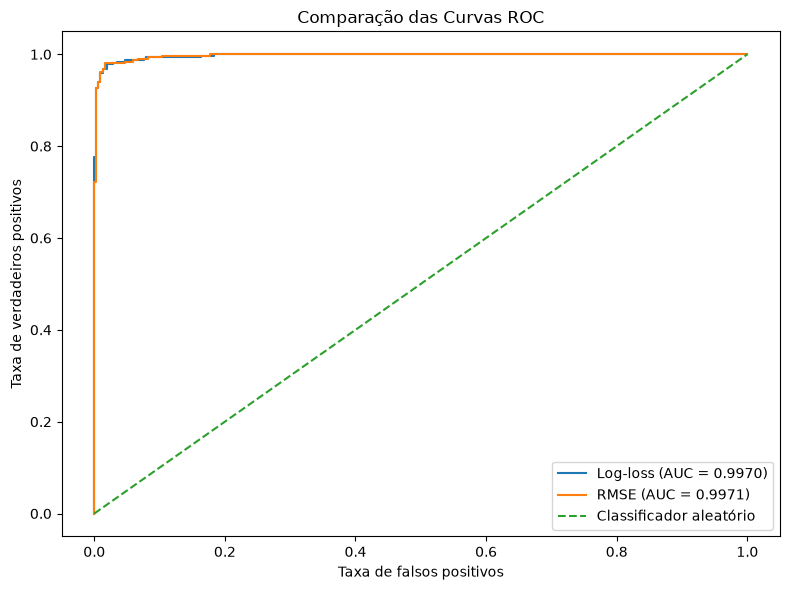

In [13]:
# Curvas ROC
fpr_log, tpr_log, _ = roc_curve(
    y_test_bin,
    y_prob_logloss
)

fpr_rmse, tpr_rmse, _ = roc_curve(
    y_test_bin,
    y_prob_rmse
)

auc_log = roc_auc_score(y_test_bin, y_prob_logloss)
auc_rmse = roc_auc_score(y_test_bin, y_prob_rmse)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Log-loss (AUC = {auc_log:.4f})"
)

plt.plot(
    fpr_rmse,
    tpr_rmse,
    label=f"RMSE (AUC = {auc_rmse:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Classificador aleatório"
)

plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Comparação das Curvas ROC")
plt.legend()
plt.tight_layout()
plt.savefig("curvas_roc.png", dpi=150)
plt.show()

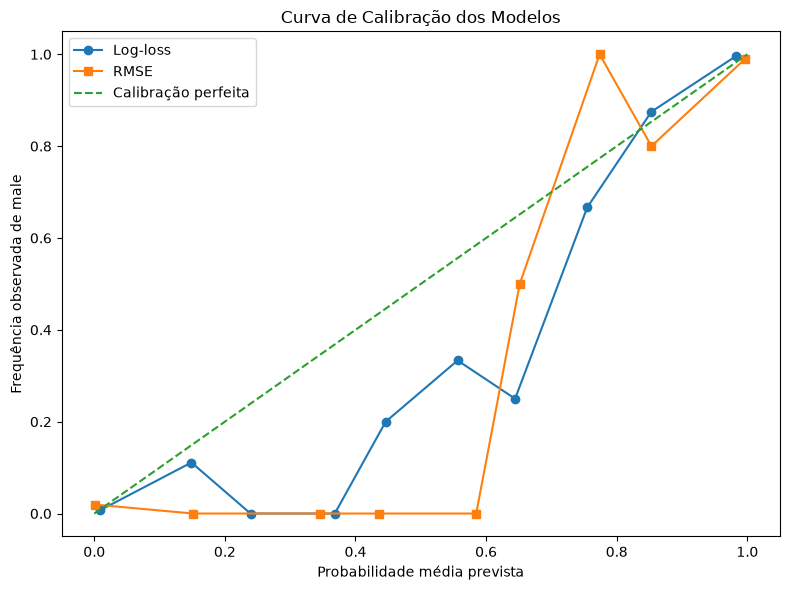

In [14]:
# Curvas de calibração
fracao_log, media_log = calibration_curve(
    y_test_bin,
    y_prob_logloss,
    n_bins=10,
    strategy="uniform"
)

fracao_rmse, media_rmse = calibration_curve(
    y_test_bin,
    y_prob_rmse,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    media_log,
    fracao_log,
    marker="o",
    label="Log-loss"
)

plt.plot(
    media_rmse,
    fracao_rmse,
    marker="s",
    label="RMSE"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibração perfeita"
)

plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência observada de male")
plt.title("Curva de Calibração dos Modelos")
plt.legend()
plt.tight_layout()
plt.savefig("curva_calibracao.png", dpi=150)
plt.show()